<a href="https://colab.research.google.com/github/kyuhyunglee/Brain-to-Text-decoding-network/blob/main/BCIMainController.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()

⏬ Downloading https://github.com/jaimergp/miniforge/releases/download/24.11.2-1_colab/Miniforge3-colab-24.11.2-1_colab-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:07
🔁 Restarting kernel...


In [ ]:
# Conda 이용한 가상환경 설정
# 너무 이전 패키지들이라 충돌 발생 - 특히 tensorflow 1.15는 PyPI로 밖에 받는 게 남아있지 않음
# 코랩에서는 파이썬 3.8 이상 밖에 호환이 안되며, 커스텀으로 바꾸지도 못해서 가상환경이 필수이다.
import condacolab
condacolab.check()

!conda create -n bci python=3.7 numpy=1.17 scipy=1.1.0 scikit-learn=0.20 -y

✨🍰✨ Everything looks OK!
Channels:
 - conda-forge
Platform: linux-64
Solving environment: / - done


==> WARNING: A newer version of conda exists. <==
    current version: 24.11.2
    latest version: 26.1.0

Please update conda by running

    $ conda update -n base -c conda-forge conda



## Package Plan ##

  environment location: /usr/local/envs/bci

  added / updated specs:
    - numpy=1.17
    - python=3.7
    - scikit-learn=0.20
    - scipy=1.1.0


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _openmp_mutex-4.5          |           20_gnu          28 KB  conda-forge
    blas-1.1                   |         openblas           1 KB  conda-forge
    ca-certificates-2026.1.4   |       hbd8a1cb_0         143 KB  conda-forge
    icu-78.2                   |       h33c6efd_0        12.1 MB  conda-forge
    ld_impl_linux-64-2.45.1    |default_hbd61a6d_101         709 KB  conda-forge


In [ ]:
!/usr/local/envs/bci/bin/pip install --default-timeout=1000 tensorflow-gpu==1.15

  Using cached tensorflow_gpu-1.15.0-cp37-cp37m-manylinux2010_x86_64.whl.metadata (2.6 kB)
  Using cached absl_py-2.1.0-py3-none-any.whl.metadata (2.3 kB)
  Using cached astor-0.8.1-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached gast-0.2.2.tar.gz (10 kB)
  Preparing metadata (setup.py) ... done
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached Keras_Applications-1.0.8-py3-none-any.whl.metadata (1.7 kB)
  Using cached Keras_Preprocessing-1.1.2-py2.py3-none-any.whl.metadata (1.9 kB)
  Using cached opt_einsum-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
  Using cached protobuf-4.24.4-cp37-abi3-manylinux2014_x86_64.whl.metadata (540 bytes)
  Using cached tensorboard-1.15.0-py3-none-any.whl.metadata (1.8 kB)
  Using cached tensorflow_estimator-1.15.1-py2.py3-none-any.whl.metadata (1.3 kB)
  Using cached termcolor-2.3.0-py3-none-any.whl.metadata (5.3 kB)
  Using cached wrapt-1.16.0-cp37-c

In [ ]:
# twpca 설치 (기존 설치된 라이브러리 버전(tensorflow)을 건드리지 않도록 --no-deps 사용)
!/usr/local/envs/bci/bin/pip install --no-deps git+https://github.com/ganguli-lab/twpca

# twpca가 필요로 하는 tqdm은 별도로 안전하게 설치
!/usr/local/envs/bci/bin/pip install tqdm

!/usr/local/envs/bci/bin/pip install matplotlib jupyter

!/usr/local/envs/bci/bin/pip install protobuf==3.20.3

  Cloning https://github.com/ganguli-lab/twpca to /tmp/pip-req-build-n1ai3rd6
  Running command git clone --filter=blob:none --quiet https://github.com/ganguli-lab/twpca /tmp/pip-req-build-n1ai3rd6
  Resolved https://github.com/ganguli-lab/twpca to commit bbefdb39f13200f7796987323521d72823412f39
  Preparing metadata (setup.py) ... done
  Created wheel for twpca: filename=twpca-0.0.3-py3-none-any.whl size=14903 sha256=c36069855f9c0e707ad9ba335f6fca6bf479296ea75d035fca174a52f43000b8
  Stored in directory: /tmp/pip-ephem-wheel-cache-zo37a7h9/wheels/b2/0f/57/76307feff47888754b97e0cf0d563c3aa97bc48d40b7f17442
Successfully built twpca
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 8.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
twpca 0.0.3 requires tensorflo

In [ ]:
# CUDA 10.0 및 cuDNN 7.6 설치 (TF 1.15 필수 요구사항)
# 시간이 조금 걸릴 수 있습니다.
!mamba install -n bci cudatoolkit=10.0 cudnn=7.6 -c anaconda -y


Looking for: ['cudatoolkit=10.0', 'cudnn=7.6']

[+] 0.0s
anaconda/linux-64 (check zst)                      Checked  0.1s
[+] 0.0s
anaconda/noarch (c..  ⣾  anaconda/noarch (check zst)                       
warning  libmamba Could not parse mod/etag header
warning  libmamba Could not parse mod/etag header
[+] 0.0s
anaconda/linux-64  ⣾  [+] 0.1s
conda-forge/linux-64  ⣾  
conda-forge/noarch    ⣾  
anaconda/linux-64      2%
anaconda/noarch       ⣾  anaconda/noarch                                   
[+] 0.2s
conda-forge/linux-64   3%
conda-forge/noarch     7%
anaconda/linux-64     87%anaconda/linux-64                                 
[+] 0.3s
conda-forge/linux-64   9%
conda-forge/noarch    19%[+] 0.4s
conda-forge/linux-64  17%
conda-forge/noarch    36%[+] 0.5s
conda-forge/linux-64  27%
conda-forge/noarch    56%[+] 0.6s
conda-forge/linux-64  36%
conda-forge/noarch    76%[+] 0.7s
conda-forge/linux-64  47%
conda-forge/noarch    98%conda-forge/noarch                                
[+] 0.8s
c

In [ ]:
!/usr/local/envs/bci/bin/python -c "import tensorflow as tf; print(f'TF Version: {tf.__version__}')"
!find /usr/local/envs/bci -name "libcudart.so.10.0"

TF Version: 1.15.0
/usr/local/envs/bci/lib/libcudart.so.10.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# 프로젝트 폴더 경로 설정 (사용자 지정 경로)
projectDir = '/content/drive/MyDrive/handwritingBCI-main'

# 작업 디렉토리를 프로젝트 폴더로 변경
os.chdir(projectDir)
print(f"현재 작업 위치: {os.getcwd()}")

현재 작업 위치: /content/drive/MyDrive/handwritingBCI-main


In [ ]:
# Step 1 ipynb 파일을 py 파일로 변환
!jupyter nbconvert --to python Step1_timeWarp.ipynb

# 변환된 파일 확인
!ls -lh Step1_timeWarp.py

# bci 가상환경으로 실행
print("Step 1 실행 시작...")
!/usr/local/envs/bci/bin/python Step1_timeWarp.py

Step 1 실행 시작...
/usr/local/envs/bci/lib/python3.7/site-packages/sklearn/utils/validation.py:37: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  LARGE_SPARSE_SUPPORTED = LooseVersion(scipy_version) >= '0.14.0'
Warping dataset: t5.2019.05.08
Warping character: a
2026-01-12 12:37:29.272726: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcuda.so.1
2026-01-12 12:37:29.294996: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:983] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-01-12 12:37:29.295198: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1618] Found device 0 with properties: 
name: Tesla T4 major: 7 minor: 5 memoryClockRate(GHz): 1.59
pciBusID: 0000:00:04.0
2026-01-12 12:37:29.295474: W tensorflow/stream_executor/platform/default/dso_loader.cc:55] Could not load dynamic library 'libcud

In [ ]:
# Step 2 노트북을 Python 스크립트로 변환
# (반드시 _walkthrough가 아닌 본 파일을 변환해야 합니다!)
!jupyter nbconvert --to python Step2_hmmDataLabeling.ipynb

# 변환된 파일 확인
!ls -lh Step2_hmmDataLabeling.py

# bci 가상환경으로 실행
print("Step 2: HMM Data Labeling 시작... (데이터 레이블링은 시간이 꽤 걸립니다)")
!/usr/local/envs/bci/bin/python Step2_hmmDataLabeling.py

[NbConvertApp] Converting notebook Step2_hmmDataLabeling.ipynb to python
[NbConvertApp] Writing 4895 bytes to Step2_hmmDataLabeling.py
-rw------- 1 root root 4.8K Jan 13 13:59 Step2_hmmDataLabeling.py
Step 2: HMM Data Labeling 시작... (데이터 레이블링은 시간이 꽤 걸립니다)
/usr/local/envs/bci/lib/python3.7/site-packages/sklearn/utils/validation.py:37: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  LARGE_SPARSE_SUPPORTED = LooseVersion(scipy_version) >= '0.14.0'
Labeling t5.2019.05.08 dataset
Labeling 'HeldOutBlocks' partition
HMM Iteration 0
HMM Iteration 1
Labeling 'HeldOutTrials' partition
HMM Iteration 0
HMM Iteration 1
Total time taken: 2462.43933 seconds
 
Labeling t5.2019.11.25 dataset
Labeling 'HeldOutBlocks' partition
HMM Iteration 0
HMM Iteration 1
Labeling 'HeldOutTrials' partition
HMM Iteration 0
HMM Iteration 1
Total time taken: 1599.819038 seconds
 
Labeling t5.2019.12.09 dataset
Labeling 'HeldOutBlocks' partition
HMM Iteration 0
HMM Iteration

In [ ]:
# Step 3 노트북을 Python 스크립트로 변환
!jupyter nbconvert --to python Step3_syntheticDataAugmentation.ipynb

# 변환된 파일 확인
!ls -lh Step3_syntheticDataAugmentation.py

# bci 가상환경으로 실행
print("Step 3: generating synthetic sentences... ")
!/usr/local/envs/bci/bin/python Step3_syntheticDataAugmentation.py

[NbConvertApp] Converting notebook Step3_syntheticDataAugmentation.ipynb to python
[NbConvertApp] Writing 6988 bytes to Step3_syntheticDataAugmentation.py
-rw------- 1 root root 6.9K Jan 14 11:09 Step3_syntheticDataAugmentation.py
Step 3: generating synthetic sentences... 
/usr/local/envs/bci/lib/python3.7/site-packages/sklearn/utils/validation.py:37: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  LARGE_SPARSE_SUPPORTED = LooseVersion(scipy_version) >= '0.14.0'
Processing t5.2019.05.08
--HeldOutBlocks
--HeldOutTrials
Processing t5.2019.11.25
--HeldOutBlocks
--HeldOutTrials
Processing t5.2019.12.09
--HeldOutBlocks
--HeldOutTrials
Processing t5.2019.12.11
--HeldOutBlocks
--HeldOutTrials
Processing t5.2019.12.18
--HeldOutBlocks
--HeldOutTrials
Processing t5.2019.12.20
--HeldOutBlocks
--HeldOutTrials
Processing t5.2020.01.06
--HeldOutBlocks
--HeldOutTrials
Processing t5.2020.01.08
--HeldOutBlocks
--HeldOutTrials
Processing t5.2020.01.13
--Hel

📂 분석할 파일: /content/drive/MyDrive/handwritingBCI_data/doi_10_5061_dryad_wh70rxwmv__v20211015 (Unzipped Files)/handwritingBCIData.tar (Unzipped Files)/handwritingBCIData/RNNTrainingSteps/Step3_SyntheticSentences/HeldOutTrials/t5.2019.05.08_syntheticSentences/bat_7.tfrecord

🔹 데이터 복원 성공!
   - Time Steps: 1200
   - Input Shape: (1200, 192) (Time x 192)
   - Label Shape: (1200, 32) (Time x 32)


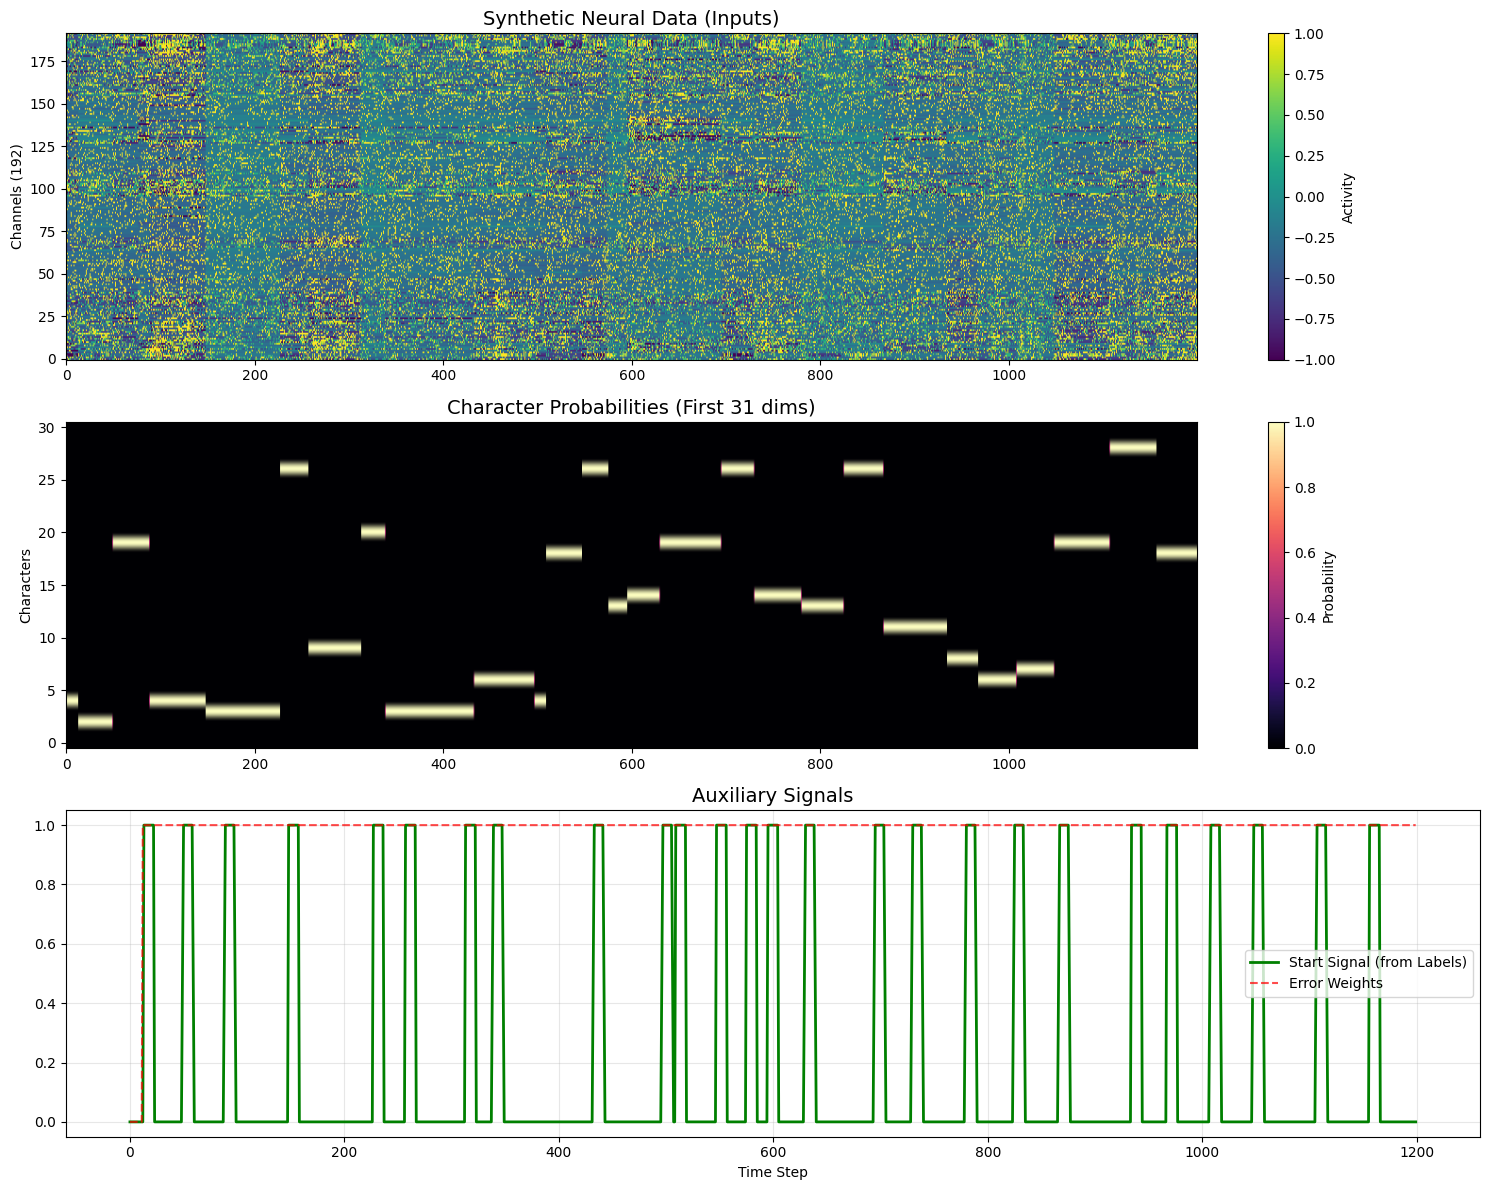

✅ 시각화 완료: 데이터가 정상적으로 생성되었습니다!


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import glob

# 파일 경로 설정
rootDir = '/content/drive/MyDrive/handwritingBCI_data/doi_10_5061_dryad_wh70rxwmv__v20211015/handwritingBCIData_Unzipped/handwritingBCIData/'
sub_folder = 'HeldOutTrials'
base_dir = os.path.join(rootDir, 'RNNTrainingSteps', 'Step3_SyntheticSentences', sub_folder)

# 파일 찾기
tfrecord_files = glob.glob(os.path.join(base_dir, '**', '*.tfrecord'), recursive=True)
target_file = tfrecord_files[0]
print(f"📂 분석할 파일: {target_file}")

# 파싱 함수 정의 (발견된 키 'inputs', 'labels', 'errWeights' 사용)
def parse_tfrecord_fn(example):
    feature_description = {
        'inputs': tf.io.VarLenFeature(tf.float32),
        'labels': tf.io.VarLenFeature(tf.float32),
        'errWeights': tf.io.VarLenFeature(tf.float32),
    }
    example = tf.io.parse_single_example(example, feature_description)

    # Sparse -> Dense 변환
    inputs_flat = tf.sparse.to_dense(example['inputs'])
    labels_flat = tf.sparse.to_dense(example['labels'])
    errWeights_flat = tf.sparse.to_dense(example['errWeights'])

    return inputs_flat, labels_flat, errWeights_flat

# 데이터 로드 및 형태 복원
raw_dataset = tf.data.TFRecordDataset(target_file)
parsed_dataset = raw_dataset.map(parse_tfrecord_fn)

for inputs_flat, labels_flat, errWeights_flat in parsed_dataset.take(1):
    # numpy 변환
    inputs_flat = inputs_flat.numpy()
    labels_flat = labels_flat.numpy()
    errWeights_flat = errWeights_flat.numpy()

    n_channels = 192
    n_time_steps = int(len(inputs_flat) / n_channels)

    inputs = inputs_flat.reshape(n_time_steps, n_channels)

    n_classes = int(len(labels_flat) / n_time_steps)
    labels = labels_flat.reshape(n_time_steps, n_classes)

    errWeights = errWeights_flat.reshape(n_time_steps, 1)

    print(f"\n🔹 데이터 복원 성공!")
    print(f"   - Time Steps: {n_time_steps}")
    print(f"   - Input Shape: {inputs.shape} (Time x 192)")
    print(f"   - Label Shape: {labels.shape} (Time x {n_classes})")

    # 시각화
    plt.figure(figsize=(15, 12))

    plt.subplot(3, 1, 1)
    plt.imshow(inputs.T, aspect='auto', cmap='viridis', origin='lower', vmin=-1, vmax=1)
    plt.title('Synthetic Neural Data (Inputs)', fontsize=14)
    plt.ylabel('Channels (192)')
    plt.colorbar(label='Activity')

    prob_targets = labels[:, :-1] # 마지막 하나 빼고 나머지
    start_target = labels[:, -1]  # 마지막 하나

    plt.subplot(3, 1, 2)
    plt.imshow(prob_targets.T, aspect='auto', cmap='magma', origin='lower')
    plt.title(f'Character Probabilities (First {n_classes-1} dims)', fontsize=14)
    plt.ylabel('Characters')
    plt.colorbar(label='Probability')

    # 보조 신호
    plt.subplot(3, 1, 3)
    plt.plot(start_target, label='Start Signal (from Labels)', color='green', linewidth=2)
    plt.plot(errWeights, label='Error Weights', color='red', linestyle='--', alpha=0.7)
    plt.title('Auxiliary Signals', fontsize=14)
    plt.xlabel('Time Step')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("✅ 시각화 완료: 데이터가 정상적으로 생성되었습니다!")

In [ ]:
# 여기서는 기존 노트북 코드를 변환한 다음 바로 사용해서는 안된다.
# 코랩환경과는 맞지 않는 백그라운드 학습 후 실시간 시각화를 하기 때문에 .py 파일을 직접 열어서 바꿔준다.
# 런타임 종료 후에는 .py 없어지기 때문에 계속 실행해 주어야 한다.
%%writefile Step4_rnnTraining.py

import tensorflow as tf
import os
import sys

# tensorflow 2.x 버전의 행동은 모두 제외시킨다.
# 이를 제일 우선으로 실행한다.
try:
    tf.compat.v1.disable_v2_behavior()
    print("✅ TensorFlow 2.x Behavior Disabled (Full V1 Compatibility Mode)")
except AttributeError:
    print("⚠️ Warning: disable_v2_behavior not found. Trying disable_eager_execution...")
    if tf.executing_eagerly():
        tf.compat.v1.disable_eager_execution()

tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.INFO)

# 그 다음 나머지 임포트
import numpy as np
import scipy.io
import pickle
from charSeqRNN import charSeqRNN, getDefaultRNNArgs

#point this towards the top level dataset directory
rootDir = '/content/drive/MyDrive/handwritingBCI_data/doi_10_5061_dryad_wh70rxwmv__v20211015/handwritingBCIData_Unzipped/handwritingBCIData/'

#use this train/test partition
cvPart = 'HeldOutTrials'

outputDir = rootDir + 'RNNTrainingSteps/Step4_RNNTraining/' + cvPart

target_step = 45000
ckpt_file_path = os.path.join(outputDir, 'checkpoint')

if os.path.exists(os.path.join(outputDir, f'model.ckpt-{target_step}.index')):
    print(f"✅ 목표 체크포인트 파일 발견: {target_step}")

    new_content = f'model_checkpoint_path: "model.ckpt-{target_step}"\n'
    new_content += f'all_model_checkpoint_paths: "model.ckpt-{target_step}"\n'

    with open(ckpt_file_path, 'w') as f:
      f.write(new_content)
    print(f" checkpoint 파일을 수정했습니다! 이제 학습기가 무조건 {target_step}번부터 로드합니다.")
else:
    print("지정한 체크포인트 파일이 없습니다.")

# . 설정 로드 (args.p 있으면 로드, 없으면 생성)
args_path = outputDir + '/args.p'

if os.path.exists(args_path):
    print("🔄 기존 설정(args.p) 로드 중...")
    args = pickle.load(open(args_path, "rb"))

else:
    print("기존 설정이 없어 새로 생성합니다.")

    rnnOutputDir = cvPart

    #train an RNN using data from these specified sessions
    dataDirs = ['t5.2019.05.08','t5.2019.11.25','t5.2019.12.09','t5.2019.12.11','t5.2019.12.18',
            't5.2019.12.20','t5.2020.01.06','t5.2020.01.08','t5.2020.01.13','t5.2020.01.15']

    if not os.path.isdir(rootDir + 'RNNTrainingSteps/Step4_RNNTraining'):
        os.mkdir(rootDir + 'RNNTrainingSteps/Step4_RNNTraining')
    if not os.path.isdir(outputDir):
        os.mkdir(outputDir)

    #We will use the default arguments specified here
    args = getDefaultRNNArgs()

    #Configure the arguments for a multi-day RNN (that will have a unique input layer for each day)
    for x in range(len(dataDirs)):
        args['sentencesFile_'+str(x)] = rootDir+'Datasets/'+dataDirs[x]+'/sentences.mat'
        args['singleLettersFile_'+str(x)] = rootDir+'Datasets/'+dataDirs[x]+'/singleLetters.mat'
        args['labelsFile_'+str(x)] = rootDir+'RNNTrainingSteps/Step2_HMMLabels/'+cvPart+'/'+dataDirs[x]+'_timeSeriesLabels.mat'
        args['syntheticDatasetDir_'+str(x)] = rootDir+'RNNTrainingSteps/Step3_SyntheticSentences/'+cvPart+'/'+dataDirs[x]+'_syntheticSentences/'
        args['cvPartitionFile_'+str(x)] = rootDir+'RNNTrainingSteps/trainTestPartitions_'+cvPart+'.mat'
        args['sessionName_'+str(x)] = dataDirs[x]

    args['outputDir'] = rootDir+'RNNTrainingSteps/Step4_RNNTraining/'+rnnOutputDir
    if not os.path.isdir(args['outputDir']):
        os.mkdir(args['outputDir'])

    #this weights each day equally (0.1 probability for each day) and allocates a unique input layer for each day (0-9)
    args['dayProbability'] = '[0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1]'
    args['dayToLayerMap'] = '[0,1,2,3,4,5,6,7,8,9]'

args['outputDir'] = outputDir   # 현재 저장 경로
args['loadDir'] = outputDir     # [중요] 불러올 경로를 저장 경로와 같게 설정
args['mode'] = 'train'          # 학습 모드

#save the arguments dictionary so that the RNN program can load it
pickle.dump(args, open(args_path, "wb"))

# In[ ]:

# 자동으로 학습 시작
rnn = charSeqRNN(args)
rnn.train()




Overwriting Step4_rnnTraining.py


In [ ]:
# Step 4 실행 (GPU 0번 사용)
# CUDA 10.0 버전 필요(너무 최신 버전이면 안된다)
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

print("Step 4: RNN 모델 학습 Start")
# 학습 로그가 실시간으로 출력될 것입니다.
!export LD_LIBRARY_PATH=$LD_LIBRARY_PATH:/usr/local/envs/bci/lib && \
 /usr/local/envs/bci/bin/python Step4_rnnTraining.py

Step 4: RNN 모델 학습 Start
Instructions for updating:
non-resource variables are not supported in the long term
✅ TensorFlow 2.x Behavior Disabled (Full V1 Compatibility Mode)
✅ 목표 체크포인트 파일 발견: 45000
 checkpoint 파일을 수정했습니다! 이제 학습기가 무조건 45000번부터 로드합니다.
🔄 기존 설정(args.p) 로드 중...


2026-01-23 10:36:04.324108: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcuda.so.1
2026-01-23 10:36:04.343917: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:983] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-01-23 10:36:04.344126: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1618] Found device 0 with properties: 
name: Tesla T4 major: 7 minor: 5 memoryClockRate(GHz): 1.59
pciBusID: 0000:00:04.0
2026-01-23 10:36:04.344419: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudart.so.10.0
2026-01-23 10:36:

분석 경로: /content/drive/MyDrive/handwritingBCI_data/doi_10_5061_dryad_wh70rxwmv__v20211015/handwritingBCIData_Unzipped/handwritingBCIData/RNNTrainingSteps/Step4_RNNTraining/HeldOutTrials
 로그 파일 발견! 데이터를 로드합니다...


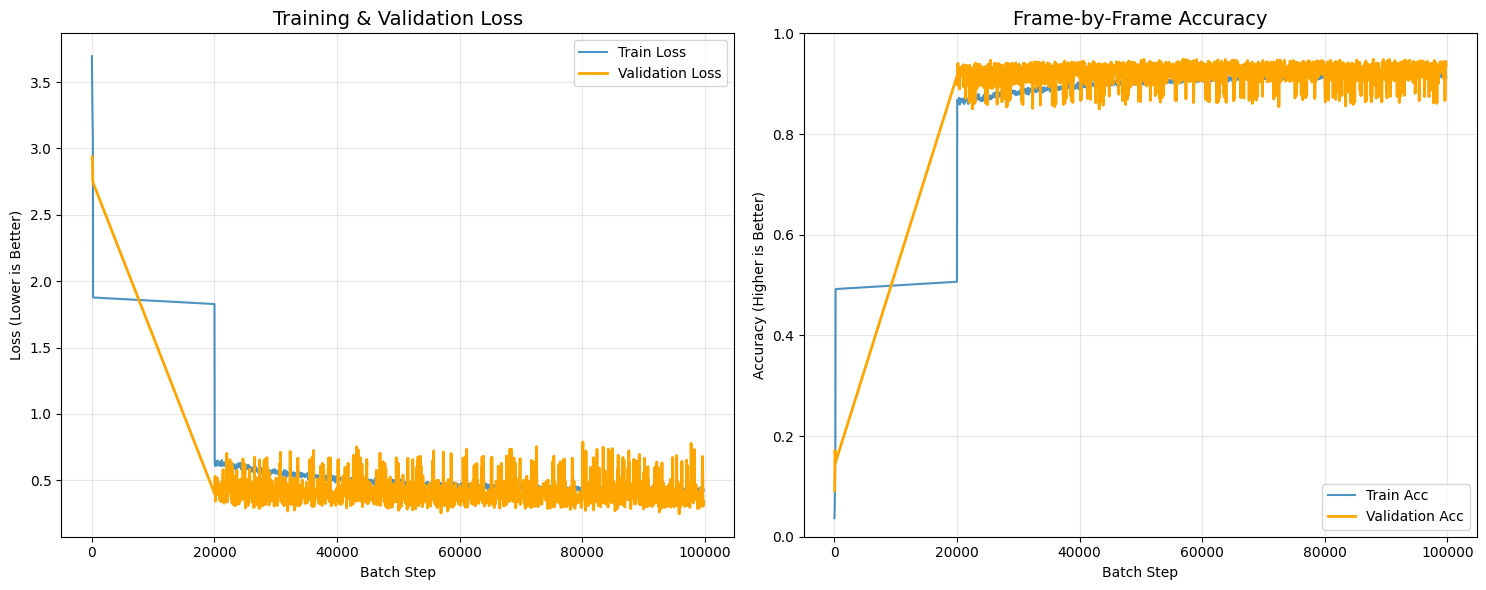


 [모델 예측 성능 확인] 위: 모델의 예측 / 아래: 실제 정답


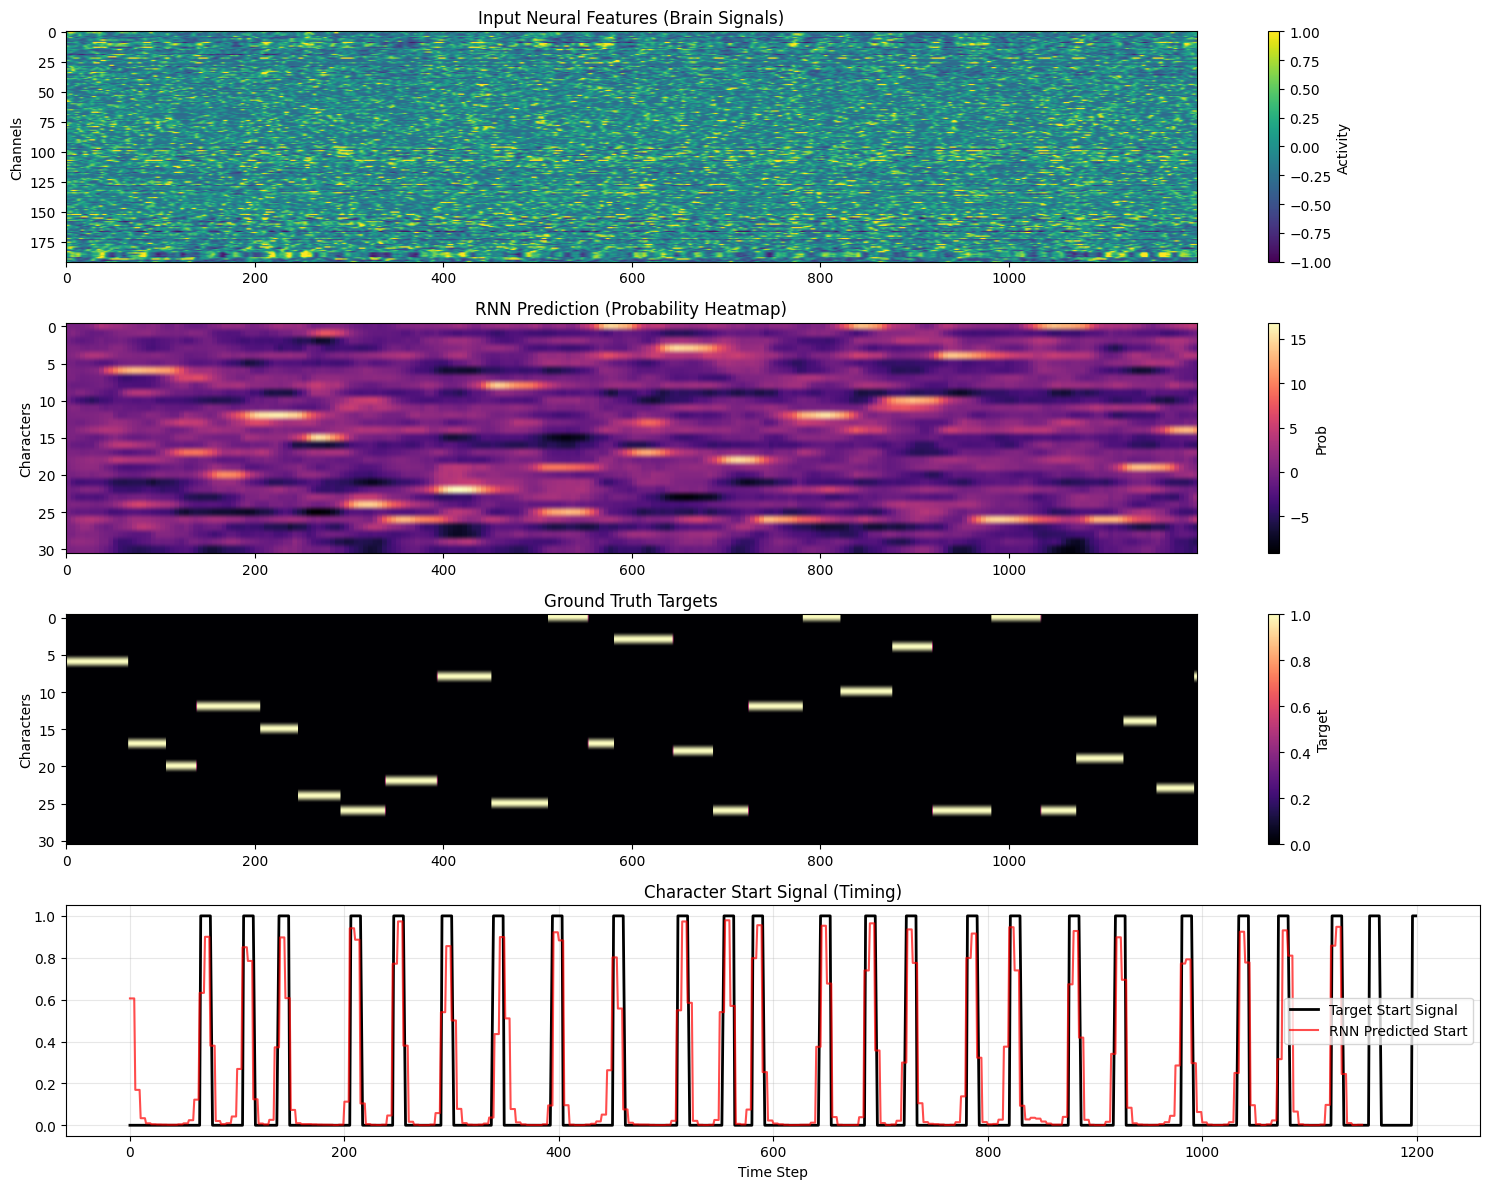

In [ ]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
import os

# 파일 경로 설정
rootDir = '/content/drive/MyDrive/handwritingBCI_data/doi_10_5061_dryad_wh70rxwmv__v20211015/handwritingBCIData_Unzipped/handwritingBCIData/'
cvPart = 'HeldOutTrials'

# Step 4 결과가 저장된 폴더
outputDir = os.path.join(rootDir, 'RNNTrainingSteps', 'Step4_RNNTraining', cvPart)

print(f"분석 경로: {outputDir}")

# 데이터 로드
log_file = os.path.join(outputDir, 'intermediateOutput.mat')
snapshot_file = os.path.join(outputDir, 'outputSnapshot.mat')

if not os.path.exists(log_file) or not os.path.exists(snapshot_file):
    print("결과 파일을 찾을 수 없습니다.")
    print("학습이 조금이라도 진행되어야 파일이 생성됩니다.")
else:
    print(" 로그 파일 발견! 데이터를 로드합니다...")
    logs = scipy.io.loadmat(log_file)
    snap = scipy.io.loadmat(snapshot_file)

    # 학습 곡선 (Loss & Accuracy)
    train_stats = logs['batchTrainStats']
    val_stats = logs['batchValStats']

    # 0으로 채워진 빈 행 제거 (아직 학습 안 된 부분)
    train_stats = train_stats[train_stats[:, 0] > 0]
    val_stats = val_stats[val_stats[:, 0] > 0]

    plt.figure(figsize=(15, 6))

    #  Loss 그래프
    plt.subplot(1, 2, 1)
    plt.plot(train_stats[:, 0], gaussian_filter1d(train_stats[:, 1], 20), label='Train Loss', alpha=0.8)
    plt.plot(val_stats[:, 0], val_stats[:, 1], label='Validation Loss', linewidth=2, color='orange')
    plt.title('Training & Validation Loss', fontsize=14)
    plt.xlabel('Batch Step')
    plt.ylabel('Loss (Lower is Better)')
    plt.legend()
    plt.grid(True, alpha=0.3)

    #  Accuracy 그래프
    plt.subplot(1, 2, 2)
    plt.plot(train_stats[:, 0], gaussian_filter1d(train_stats[:, 3], 20), label='Train Acc', alpha=0.8)
    plt.plot(val_stats[:, 0], val_stats[:, 3], label='Validation Acc', linewidth=2, color='orange')
    plt.title('Frame-by-Frame Accuracy', fontsize=14)
    plt.xlabel('Batch Step')
    plt.ylabel('Accuracy (Higher is Better)')
    plt.ylim([0, 1.0])
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # 모델 예측 시각화 (Snapshot)
    print("\n [모델 예측 성능 확인] 위: 모델의 예측 / 아래: 실제 정답")

    plt.figure(figsize=(15, 12))

    # 입력 뇌신호
    plt.subplot(4, 1, 1)
    plt.imshow(snap['inputs'].T, aspect='auto', cmap='viridis', vmin=-1, vmax=1)
    plt.title('Input Neural Features (Brain Signals)', fontsize=12)
    plt.ylabel('Channels')
    plt.colorbar(label='Activity')

    # RNN 예측 확률 (Logits)
    plt.subplot(4, 1, 2)
    plt.imshow(snap['charProbOutput'].T, aspect='auto', cmap='magma', origin='upper')
    plt.title('RNN Prediction (Probability Heatmap)', fontsize=12)
    plt.ylabel('Characters')
    plt.colorbar(label='Prob')

    # 실제 정답
    plt.subplot(4, 1, 3)
    plt.imshow(snap['charProbTarget'].T, aspect='auto', cmap='magma', origin='upper')
    plt.title('Ground Truth Targets', fontsize=12)
    plt.ylabel('Characters')
    plt.colorbar(label='Target')

    # 시작 신호
    plt.subplot(4, 1, 4)
    plt.plot(snap['charStartTarget'].flatten(), label='Target Start Signal', color='black', linewidth=2)
    plt.plot(snap['charStartOutput'].flatten(), label='RNN Predicted Start', color='red', alpha=0.7)
    plt.title('Character Start Signal (Timing)', fontsize=12)
    plt.xlabel('Time Step')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [ ]:
# Step 5 노트북을 파이썬 스크립트 변환
!jupyter nbconvert --to python Step5_rnnInference.ipynb

#TF 1.15 버전문제로 V2 버전 무시 코드를 Step5_rnninference.py에 추가해야 할 수도 있다.
#역시 필요없었다!

# 변환한 파이썬 스크립트 실행
print("Step 5: Baseline Code Inference 실행")
!export LD_LIBRARY_PATH=$LD_LIBRARY_PATH:/usr/local/envs/bci/lib && \
 /usr/local/envs/bci/bin/python Step5_rnnInference.py

[NbConvertApp] Converting notebook Step5_rnnInference.ipynb to python
[NbConvertApp] Writing 6831 bytes to Step5_rnnInference.py
Step 5: Baseline Code Inference 실행 🚀
 
Processing dataset t5.2019.05.08
2026-01-24 01:32:15.580907: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcuda.so.1
2026-01-24 01:32:15.604023: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:983] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-01-24 01:32:15.604267: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1618] Found device 0 with properties: 
name: Tesla T4 major: 7 minor: 5 memoryClockRate(GHz): 1.59
pciBusID: 0000:00:04.0
2026-01-24 01:32:15.604572: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudart.so.10.0
2026-01-24 01:32:15.605821: I tensorflow/stream_executor/platform/default/dso_loader.cc:44]

In [ ]:
import torch
import torch.nn as nn
import time
import numpy as np

# 1. Baseline Model Definition (PyTorch)
class BaselineRNN(nn.Module):
    def __init__(self, input_size=192, hidden_size=512, num_layers=2, num_classes=32):
        super(BaselineRNN, self).__init__()
        # 논문 스펙: 2-layer GRU, 512 units
        self.rnn = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=False # 논문은 Unidirectional GRU 사용 (실시간성 때문)
        )
        # Output Layer
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (Batch, Time, Input)
        # GRU Output: (Batch, Time, Hidden)
        rnn_out, _ = self.rnn(x)

        # Linear Projection
        logits = self.fc(rnn_out)
        return logits

def measure_baseline_pytorch(device='cuda'):
    # 모델 초기화
    model = BaselineRNN().to(device)
    model.eval()

    # ---------------------------------------------------------
    # 2. 파라미터 개수 측정
    # ---------------------------------------------------------
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"\n{'='*40}")
    print(f" 📊 BASELINE (RNN) PARAMETERS (PyTorch Impl)")
    print(f"{'='*40}")
    print(f" Architecture: 2-layer GRU (512 units)")
    print(f" Total Params: {total_params:,}")
    print(f"{'='*40}")

    # ---------------------------------------------------------
    # 3. 추론 속도 측정 (Inference Latency)
    # ---------------------------------------------------------
    # 논문과 동일한 Input Shape (Batch=1, Time=12000, Channels=192)
    dummy_input = torch.randn(1, 12000, 192).to(device)

    timings = []

    # (1) Warm-up
    print("\n🔥 GPU Warming up...")
    with torch.no_grad():
        for _ in range(10):
            _ = model(dummy_input)

    # (2) 실제 측정
    print("⏱️ Measuring Latency (over 100 runs)...")
    with torch.no_grad():
        for _ in range(100):
            if device == 'cuda': torch.cuda.synchronize()
            start_time = time.time()

            _ = model(dummy_input)

            if device == 'cuda': torch.cuda.synchronize()
            end_time = time.time()

            timings.append((end_time - start_time) * 1000) # ms

    avg_lat = np.mean(timings)
    std_lat = np.std(timings)
    fps = 1000.0 / avg_lat

    print(f"\n{'='*40}")
    print(f" 🚀 BASELINE INFERENCE LATENCY (Batch=1)")
    print(f"{'='*40}")
    print(f" Mean Latency: {avg_lat:.2f} ms")
    print(f" Std Dev     : {std_lat:.2f} ms")
    print(f" FPS         : {fps:.2f}")
    print(f"{'='*40}\n")

    return total_params, avg_lat

# 실행
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
measure_baseline_pytorch(device)


 📊 BASELINE (RNN) PARAMETERS (PyTorch Impl)
 Architecture: 2-layer GRU (512 units)
 Total Params: 2,676,768

🔥 GPU Warming up...
⏱️ Measuring Latency (over 100 runs)...

 🚀 BASELINE INFERENCE LATENCY (Batch=1)
 Mean Latency: 399.47 ms
 Std Dev     : 1.77 ms
 FPS         : 2.50



(2676768, np.float64(399.4693636894226))